Products can have multiple geometric representations.
Each representation belongs to a representation context. This determines how it will be viewed.
Use Types and Materials sets

The below sets up the libraries and other things needed before geometry creation.
 - Measurement units
 - Add contexts and sub contexts

Initialise the model

In [1]:
import numpy as np
import ifcopenshell.api.root
import ifcopenshell.api.unit
import ifcopenshell.api.context
import ifcopenshell.api.project
import ifcopenshell.api.geometry

model = ifcopenshell.file()

# You need a project before you can assign units.
ifcopenshell.api.root.create_entity(model, ifc_class="IfcProject")

# Let's say we want coordinates to be in millimeters.
length = ifcopenshell.api.unit.add_si_unit(model, unit_type="LENGTHUNIT", prefix="MILLI")
ifcopenshell.api.unit.assign_unit(model, units=[length])

# Alternatively, you may specify without any arguments to automatically
# create millimeters, square meters, and cubic meters as a convenience for
# testing purposes. Sorry imperial folks, we prioritise metric here.
#ifcopenshell.api.unit.assign_unit(model)



# We want our representation to be the 3D body of the element.
# This representation context is only created once per project.
# You must reuse the same body context every time you create a new representation.
model3d = ifcopenshell.api.context.add_context(model, context_type="Model")
# And/Or, if we plan to store 2D geometry, we need a "Plan" context
plan = ifcopenshell.api.context.add_context(model, context_type="Plan")

body = ifcopenshell.api.context.add_context(model,
    context_type="Model", context_identifier="Body", target_view="MODEL_VIEW", parent=model3d)


# Axis subcontext.
ifcopenshell.api.context.add_context(model,
    context_type="Model", context_identifier="Axis", target_view="GRAPH_VIEW", parent=model3d)

# It's also important to have a 2D Axis subcontext for things like
# walls and claddings which can be drawn using a 2D axis line.
ifcopenshell.api.context.add_context(model,
    context_type="Plan", context_identifier="Axis", target_view="GRAPH_VIEW", parent=plan)

# The 3D Box subcontext is useful for clash detection or shape
# analysis, or even lazy-loading of large models.
ifcopenshell.api.context.add_context(model,
    context_type="Model", context_identifier="Box", target_view="MODEL_VIEW", parent=model3d)

# A 2D annotation subcontext for plan views are important for door
# swings, window cuts, and symbols for equipment like GPOs, fire
# extinguishers, and so on.
ifcopenshell.api.context.add_context(model,
    context_type="Plan", context_identifier="Annotation", target_view="PLAN_VIEW", parent=plan)

#17=IfcGeometricRepresentationSubContext('Annotation','Plan',*,*,*,*,#12,$,.PLAN_VIEW.,$)

In [2]:

# # Create our element with an object placement.
# element = ifcopenshell.api.root.create_entity(model, ifc_class="IfcFurniture")
# ifcopenshell.api.geometry.edit_object_placement(model, product=element)

# # Let's create our representation!
# # See below sections for examples on how to create representations.
# # A wall-like representation, 5 meters long, 3 meters high, and 200mm thick
# representation = ifcopenshell.api.geometry.add_wall_representation(model,
#     context=body, length=5, height=3, thickness=0.2)

# # Assign our new body representation back to our element
# ifcopenshell.api.geometry.assign_representation(model, product=element, representation=representation)


The below code is how to make a transformation matrix to edit the object location

In [3]:
# # Create a 4x4 identity matrix. This matrix is at the origin with no rotation.
# matrix = np.eye(4)
# # Rotate the matix 90 degrees anti-clockwise around the Z axis (i.e. in plan).
# # Anti-clockwise is positive. Clockwise is negative.
# # matrix = ifcopenshell.util.placement.rotation(90, "Z") @ matrix

# # Set the X, Y, Z coordinates. Notice how we rotate first then translate.
# # This is because the rotation origin is always at 0, 0, 0.
# matrix[:,3][0:3] = (0, 4, 0)

Create IFC spaces for the rooms and corridor so they can be identified as distinct zones.

In [4]:
project = model.by_type("IfcProject")[0]
site = ifcopenshell.api.root.create_entity(model, ifc_class="IfcSite", name="Site")
building = ifcopenshell.api.root.create_entity(model, ifc_class="IfcBuilding", name="Building")
storey = model.create_entity("IfcBuildingStorey", Name="Ground", Elevation=0.0)

# IfcRelAggregates is used to define the hierarchical structure of the building model.
model.create_entity("IfcRelAggregates", RelatingObject=project, RelatedObjects=[site])
model.create_entity("IfcRelAggregates", RelatingObject=site, RelatedObjects=[building])
model.create_entity("IfcRelAggregates", RelatingObject=building, RelatedObjects=[storey])

# Define a function to add spaces to the model. 
# This function creates an IfcSpace entity, assigns it a rectangular profile representation, and relates it to the storey using IfcRelContainedInSpatialStructure.
def add_space(name, origin, width, depth, height=3.0):
    space = ifcopenshell.api.root.create_entity(model, ifc_class="IfcSpace", name=name)
    matrix = np.eye(4)
    matrix[:, 3][0:3] = origin
    ifcopenshell.api.geometry.edit_object_placement(model, product=space, matrix=matrix, is_si=True)
    profile = model.create_entity("IfcRectangleProfileDef",
        ProfileName=f"{name} footprint", ProfileType="AREA",
        XDim=width, YDim=depth)
    space_rep = ifcopenshell.api.geometry.add_profile_representation(
        model, context=body, profile=profile, depth=height)
    ifcopenshell.api.geometry.assign_representation(
        model, product=space, representation=space_rep)
    model.create_entity(
        "IfcRelContainedInSpatialStructure",
        RelatingStructure=storey,
        RelatedElements=[space])
    return space

Room1_space = add_space("Room 1", origin=(2.5, 2.1, 0.0), width=5400, depth=4200)
Room2_space = add_space("Room 2", origin=(9.2, 2.1, 0.0), width=8000, depth=4200)
Corridor_space = add_space("Corridor", origin=(6.5, 5.3, 0.0), width=13400, depth=2200)

Make Room 1

In [5]:
# make the first room
R1WN = ifcopenshell.api.root.create_entity(model, ifc_class="IfcWall")
R1WS = ifcopenshell.api.root.create_entity(model, ifc_class="IfcWall")

# A wall-like representation, 5 meters long, 3 meters high, and 200mm thick
repW1 = ifcopenshell.api.geometry.add_wall_representation(model,
    context=body, length=5, height=3, thickness=0.2)

repW2 = ifcopenshell.api.geometry.add_wall_representation(model,
    context=body, length=4.2, height=3, thickness=0.2)

matrix = np.eye(4)
matrix[:,3][0:3] = (0, 4, 0)

# Set our wall's Object Placement using our matrix.
# `is_si=True` states that we are using SI units instead of project units.
# ifcopenshell.api.geometry.edit_object_placement(model, product=wall, matrix=matrix, is_si=True)

# make the north and south walls of room 1
ifcopenshell.api.geometry.edit_object_placement(model, product=R1WS, is_si=True)
ifcopenshell.api.geometry.edit_object_placement(model, product=R1WN, matrix=matrix, is_si=True)

# Assign our new body representation back to our element
ifcopenshell.api.geometry.assign_representation(model, product=R1WS, representation=repW1)
ifcopenshell.api.geometry.assign_representation(model, product=R1WN, representation=repW1)

ifcopenshell.api.spatial.assign_container(model, relating_structure=storey, products=[R1WS, R1WN])

# make the west and south walls of room 1
R1WE = ifcopenshell.api.root.create_entity(model, ifc_class="IfcWall")
R1WW = ifcopenshell.api.root.create_entity(model, ifc_class="IfcWall")

matrix = np.eye(4)
matrix = ifcopenshell.util.placement.rotation(90, "Z") @ matrix

ifcopenshell.api.geometry.edit_object_placement(model, product=R1WE, matrix=matrix, is_si=True)
matrix[:,3][0:3] = (5.2, 0, 0)
ifcopenshell.api.geometry.edit_object_placement(model, product=R1WW, matrix=matrix, is_si=True)

ifcopenshell.api.geometry.assign_representation(model, product=R1WE, representation=repW2)
ifcopenshell.api.geometry.assign_representation(model, product=R1WW, representation=repW2)

ifcopenshell.api.spatial.assign_container(model, relating_structure=storey, products=[R1WE, R1WW])

R1slab = ifcopenshell.api.root.create_entity(model, ifc_class="IfcSlab")

# Create a rectangular profile for the slab with your desired dimensions
profile = model.create_entity("IfcRectangleProfileDef", ProfileName="slab", ProfileType="AREA",
    XDim=5400, YDim=4200)

# A profile-based representation, 1 meter long
repslab = ifcopenshell.api.geometry.add_profile_representation(model, context=body, profile=profile, depth=0.2)

matrix = np.eye(4)
matrix[:,3][0:3] = (2.5, 2.1, -0.2)
ifcopenshell.api.geometry.edit_object_placement(model, product=R1slab, matrix=matrix, is_si=True)
ifcopenshell.api.geometry.assign_representation(model, product=R1slab, representation=repslab)

ifcopenshell.api.spatial.assign_container(model, relating_structure=storey, products=[R1slab])

## make the opening for the door
R1door = ifcopenshell.api.root.create_entity(model, ifc_class="IfcOpeningElement")
doorrep = ifcopenshell.api.geometry.add_wall_representation(model,
    context=body, length=0.9, height=2.1, thickness=0.4)
ifcopenshell.api.geometry.assign_representation(model,
    product=R1door, representation=doorrep)

matrix = np.eye(4)
matrix[:,3] = [1, 4, 0, 0]
ifcopenshell.api.geometry.edit_object_placement(model, product=R1door, matrix=matrix)
ifcopenshell.api.feature.add_feature(model, feature=R1door, element=R1WN)



#177=IfcRelVoidsElement('1dXlpwmln8RRlJE06IIDPZ',$,$,$,#72,#160)

In [6]:
# Define a function to add space boundaries to the model. 
# This function creates an IfcRelSpaceBoundary entity, relates it to the space and the building element, 
# and sets the physical and internal/external attributes.

def add_space_boundary(space, element, physical="PHYSICAL", internal_external="INTERNAL", name=None):
    b = ifcopenshell.api.root.create_entity(
        model,
        ifc_class="IfcRelSpaceBoundary",
        name=name
    )
    ifcopenshell.api.boundary.edit_attributes(
        model,
        entity=b,
        relating_space=space,
        related_building_element=element
    )
    b.PhysicalOrVirtualBoundary = physical
    b.InternalOrExternalBoundary = internal_external
    return b

# Room 1 boundaries
b_north = add_space_boundary(Room1_space, R1WN, name="Room1-NorthWall")
b_south = add_space_boundary(Room1_space, R1WS, name="Room1-SouthWall")
b_east  = add_space_boundary(Room1_space, R1WE, name="Room1-EastWall")
b_west  = add_space_boundary(Room1_space, R1WW, name="Room1-WestWall")
b_floor = add_space_boundary(Room1_space, R1slab, name="Room1-Floor")

In [7]:
# adds a boundary door openings, and connects them to the space

# 1. Ensure door fills opening (you already have this)

# 2. Room 1 side boundary (already have wall boundary, but for opening:)
opening_b1 = add_space_boundary(Room1_space, R1door, name="Room1-Cor-DoorOpening")

# 3. Room 2 side boundary (new)
opening_b2 = add_space_boundary(Corridor_space, R1door, name="Cor-Room1-DoorOpening")

# 4. Optional: explicit geometry for the opening face (rectangle for door)
# From Room1 local coords (adjust to your door matrix [1,4,0])
# poly1 = model.create_entity("IfcPolyline", Points=[(0,0,0),(0.9,0,0),(0.9,2.1,0),(0,2.1,0),(0,0,0)])
# ifcopenshell.api.boundary.assign_connection_geometry(
#     model, boundary=opening_b1,
#     connection_type="POLYLOOP",  # or AXIS2_PLACEMENT_3D
# #     outer_curve=poly1  # 2D curve in space LCS
# )

In [8]:
# this can extract the local placement of the opening, which can be used to derive the geometry of the opening face if needed


space = Room1_space  # or model.by_type("IfcSpace")[0]

# for rel in space.BoundedBy:
#     elem = rel.RelatedBuildingElement
#     if elem and elem.is_a("IfcWall"):
#         print(elem)
#         print(elem.HasOpenings)


# for i in range(len(Room1_space.BoundedBy)):
#     print(Room1_space.BoundedBy[i].RelatedBuildingElement.is_a("IfcOpeningElement"))

opening = Room1_space.BoundedBy[5].RelatedBuildingElement
print(ifcopenshell.util.placement.get_local_placement(opening.ObjectPlacement))



[[1.e+00 0.e+00 0.e+00 1.e+03]
 [0.e+00 1.e+00 0.e+00 4.e+03]
 [0.e+00 0.e+00 1.e+00 0.e+00]
 [0.e+00 0.e+00 0.e+00 1.e+00]]


Make Room 2

In [9]:
# make the second room
R2WN = ifcopenshell.api.root.create_entity(model, ifc_class="IfcWall")
R2WS = ifcopenshell.api.root.create_entity(model, ifc_class="IfcWall")

# A wall-like representation, 5 meters long, 3 meters high, and 200mm thick
repW1 = ifcopenshell.api.geometry.add_wall_representation(model,
    context=body, length=8, height=3, thickness=0.2)

repW2 = ifcopenshell.api.geometry.add_wall_representation(model,
    context=body, length=4.2, height=3, thickness=0.2)



# make the north and south walls of room 2
matrix = np.eye(4)
matrix[:,3][0:3] = (5.2, 4, 0)
ifcopenshell.api.geometry.edit_object_placement(model, product=R2WN, matrix=matrix, is_si=True)
matrix[:,3][0:3] = (5.2, 0, 0)
ifcopenshell.api.geometry.edit_object_placement(model, product=R2WS, matrix=matrix, is_si=True)

# Assign our new body representation back to our element
ifcopenshell.api.geometry.assign_representation(model, product=R2WS, representation=repW1)
ifcopenshell.api.geometry.assign_representation(model, product=R2WN, representation=repW1)

# make the east walls of room 2
R2WE = ifcopenshell.api.root.create_entity(model, ifc_class="IfcWall")

matrix = np.eye(4)
matrix = ifcopenshell.util.placement.rotation(90, "Z") @ matrix
matrix[:,3][0:3] = (13.2, 0, 0)
ifcopenshell.api.geometry.edit_object_placement(model, product=R2WE, matrix=matrix, is_si=True)

ifcopenshell.api.geometry.assign_representation(model, product=R2WE, representation=repW2)

R2slab = ifcopenshell.api.root.create_entity(model, ifc_class="IfcSlab")

# Create a rectangular profile for the slab with your desired dimensions
profile = model.create_entity("IfcRectangleProfileDef", ProfileName="slab", ProfileType="AREA",
    XDim=8000, YDim=4200)

# A profile-based representation, 1 meter long
repslab = ifcopenshell.api.geometry.add_profile_representation(model, context=body, profile=profile, depth=0.2)

matrix = np.eye(4)
matrix[:,3][0:3] = (9.2, 2.1, -0.2)
ifcopenshell.api.geometry.edit_object_placement(model, product=R2slab, matrix=matrix, is_si=True)
ifcopenshell.api.geometry.assign_representation(model, product=R2slab, representation=repslab)


## make the opening for the door
R2door = ifcopenshell.api.root.create_entity(model, ifc_class="IfcOpeningElement")
doorrep = ifcopenshell.api.geometry.add_wall_representation(model,
    context=body, length=0.9, height=2.1, thickness=0.4)
ifcopenshell.api.geometry.assign_representation(model,
    product=R2door, representation=doorrep)

matrix = np.eye(4)
matrix[:,3] = [10, 4, 0, 0]
ifcopenshell.api.geometry.edit_object_placement(model, product=R2door, matrix=matrix)
ifcopenshell.api.feature.add_feature(model, feature=R2door, element=R2WN)

ifcopenshell.api.spatial.assign_container(model, relating_structure=storey, products=[R2WS, R2WN, R2WE, R2slab])


#39=IfcRelContainedInSpatialStructure($,$,$,$,(#191,#224,#116,#117,#140,#73,#24,#190,#72,#231),#20)

Make Corridor

In [10]:
# make the corridor
CWN = ifcopenshell.api.root.create_entity(model, ifc_class="IfcWall")

# A wall-like representation, 5 meters long, 3 meters high, and 200mm thick
repW1 = ifcopenshell.api.geometry.add_wall_representation(model,
    context=body, length=13, height=3, thickness=0.2)

repW2 = ifcopenshell.api.geometry.add_wall_representation(model,
    context=body, length=2.2, height=3, thickness=0.2)

matrix = np.eye(4)
matrix[:,3][0:3] = (0, 6.2, 0)

# make the north wall of corridor
ifcopenshell.api.geometry.edit_object_placement(model, product=CWN, matrix=matrix, is_si=True)

# Assign our new body representation back to our element
ifcopenshell.api.geometry.assign_representation(model, product=CWN, representation=repW1)

# make the west and east walls of corridor
CWE = ifcopenshell.api.root.create_entity(model, ifc_class="IfcWall")
CWW = ifcopenshell.api.root.create_entity(model, ifc_class="IfcWall")

matrix = np.eye(4)
matrix = ifcopenshell.util.placement.rotation(90, "Z") @ matrix
matrix[:,3][0:3] = (0, 4.2, 0)
ifcopenshell.api.geometry.edit_object_placement(model, product=CWW, matrix=matrix, is_si=True)
matrix[:,3][0:3] = (13.2, 4.2, 0)
ifcopenshell.api.geometry.edit_object_placement(model, product=CWE, matrix=matrix, is_si=True)

ifcopenshell.api.geometry.assign_representation(model, product=CWE, representation=repW2)
ifcopenshell.api.geometry.assign_representation(model, product=CWW, representation=repW2)

Cslab = ifcopenshell.api.root.create_entity(model, ifc_class="IfcSlab")

# Create a rectangular profile for the slab with your desired dimensions
profile = model.create_entity("IfcRectangleProfileDef", ProfileName="slab", ProfileType="AREA",
    XDim=13400, YDim=2200)

# A profile-based representation, 1 meter long
repslab = ifcopenshell.api.geometry.add_profile_representation(model, context=body, profile=profile, depth=0.2)

matrix = np.eye(4)
matrix[:,3][0:3] = (6.5, 5.3, -0.2)
ifcopenshell.api.geometry.edit_object_placement(model, product=Cslab, matrix=matrix, is_si=True)
ifcopenshell.api.geometry.assign_representation(model, product=Cslab, representation=repslab)


## make the opening for the corridor exit
Cdoor = ifcopenshell.api.root.create_entity(model, ifc_class="IfcOpeningElement")
doorrep = ifcopenshell.api.geometry.add_wall_representation(model,
    context=body, length=0.9, height=2.1, thickness=0.4)
ifcopenshell.api.geometry.assign_representation(model,
    product=Cdoor, representation=doorrep)

matrix = np.eye(4)
matrix = ifcopenshell.util.placement.rotation(90, "Z") @ matrix
matrix[:,3] = [13.2, 4.8, 0, 0]
ifcopenshell.api.geometry.edit_object_placement(model, product=Cdoor, matrix=matrix)
ifcopenshell.api.feature.add_feature(model, feature=Cdoor, element=CWE)

ifcopenshell.api.spatial.assign_container(model, relating_structure=storey, products=[CWN, CWE, CWW, Cslab])


#39=IfcRelContainedInSpatialStructure($,$,$,$,(#191,#224,#116,#317,#117,#140,#330,#73,#24,#190,#316,#72,#289,#231),#20)

In [11]:
print(Room1_space)

#24=IfcSpace('3BjrQAk_HBIwU7KrEdyyHk',$,'Room 1',$,$,#29,#38,$,$,$,$)


Validate that spaces align with walls and slabs


In [12]:
import pandas as pd

def validate_spaces():
    """Extract and compare space dimensions with wall/slab geometry"""
    
    # Get all spaces and their placement/representation info
    spaces = model.by_type("IfcSpace")
    slabs = model.by_type("IfcSlab")
    walls = model.by_type("IfcWall")
    
    space_data = []
    for space in spaces:
        if space.ObjectPlacement:
            placement = space.ObjectPlacement
            if hasattr(placement, 'RelativePlacement'):
                loc = placement.RelativePlacement.Location.Coordinates
                x, y, z = loc[0]/1000, loc[1]/1000, loc[2]/1000  # Convert mm to m
            else:
                x, y, z = None, None, None
        else:
            x, y, z = None, None, None
        
        # Extract dimensions from representation
        width, depth = None, None
        if space.Representation:
            for rep in space.Representation.Representations:
                for item in rep.Items:
                    if hasattr(item, 'SweptArea'):
                        profile = item.SweptArea
                        if hasattr(profile, 'XDim') and hasattr(profile, 'YDim'):
                            width = profile.XDim / 1000  # mm to m
                            depth = profile.YDim / 1000
        
        space_data.append({
            'Name': space.Name or 'Unnamed',
            'X': x,
            'Y': y,
            'Z': z,
            'Width (m)': width,
            'Depth (m)': depth
        })
    
    df_spaces = pd.DataFrame(space_data)
    
    # Get slab data (slabs define room footprints)
    slab_data = []
    for slab in slabs:
        if slab.ObjectPlacement:
            placement = slab.ObjectPlacement
            if hasattr(placement, 'RelativePlacement'):
                loc = placement.RelativePlacement.Location.Coordinates
                x, y, z = loc[0]/1000, loc[1]/1000, loc[2]/1000
            else:
                x, y, z = None, None, None
        else:
            x, y, z = None, None, None
        
        width, depth = None, None
        if slab.Representation:
            for rep in slab.Representation.Representations:
                for item in rep.Items:
                    if hasattr(item, 'SweptArea'):
                        profile = item.SweptArea
                        if hasattr(profile, 'XDim') and hasattr(profile, 'YDim'):
                            width = profile.XDim / 1000
                            depth = profile.YDim / 1000
        
        slab_data.append({
            'Name': slab.Name or 'Slab',
            'X': x,
            'Y': y,
            'Z': z,
            'Width (m)': width,
            'Depth (m)': depth
        })
    
    df_slabs = pd.DataFrame(slab_data)
    
    print("=" * 70)
    print("SPACES")
    print("=" * 70)
    print(df_spaces.to_string())
    print()
    print("=" * 70)
    print("SLABS (room footprints)")
    print("=" * 70)
    print(df_slabs.to_string())
    print()
    print("=" * 70)
    print("VALIDATION SUMMARY")
    print("=" * 70)
    
    # Compare
    for _, space in df_spaces.iterrows():
        name = space['Name']
        # Find matching slab (by approximate position)
        matching_slab = df_slabs[
            (df_slabs['X'] - space['X']).abs() < 0.1
        ]
        if len(matching_slab) > 0:
            slab = matching_slab.iloc[0]
            dx = abs(space['Width (m)'] - slab['Width (m)'])
            dy = abs(space['Depth (m)'] - slab['Depth (m)'])
            if dx < 0.1 and dy < 0.1:
                print(f"✓ {name:20} ALIGNED with slab")
            else:
                print(f"✗ {name:20} MISMATCH: space ({space['Width (m)']:.1f}m × {space['Depth (m)']:.1f}m) vs slab ({slab['Width (m)']:.1f}m × {slab['Depth (m)']:.1f}m)")
        else:
            print(f"? {name:20} No matching slab found")

validate_spaces()


SPACES
       Name    X    Y    Z  Width (m)  Depth (m)
0    Room 1  2.5  2.1  0.0        5.4        4.2
1    Room 2  9.2  2.1  0.0        8.0        4.2
2  Corridor  6.5  5.3  0.0       13.4        2.2

SLABS (room footprints)
   Name    X    Y    Z  Width (m)  Depth (m)
0  Slab  2.5  2.1 -0.2        5.4        4.2
1  Slab  9.2  2.1 -0.2        8.0        4.2
2  Slab  6.5  5.3 -0.2       13.4        2.2

VALIDATION SUMMARY
✓ Room 1               ALIGNED with slab
✓ Room 2               ALIGNED with slab
✓ Corridor             ALIGNED with slab


Visualize spaces and walls in 2D plan view

C:\Users\Richard\AppData\Local\Temp\ipykernel_22388\3006446587.py:69: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  blue_patch = patches.Patch(color='lightblue', edgecolor='blue', label='Spaces')
C:\Users\Richard\AppData\Local\Temp\ipykernel_22388\3006446587.py:70: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  red_patch = patches.Patch(color='lightcoral', edgecolor='darkred', label='Walls')


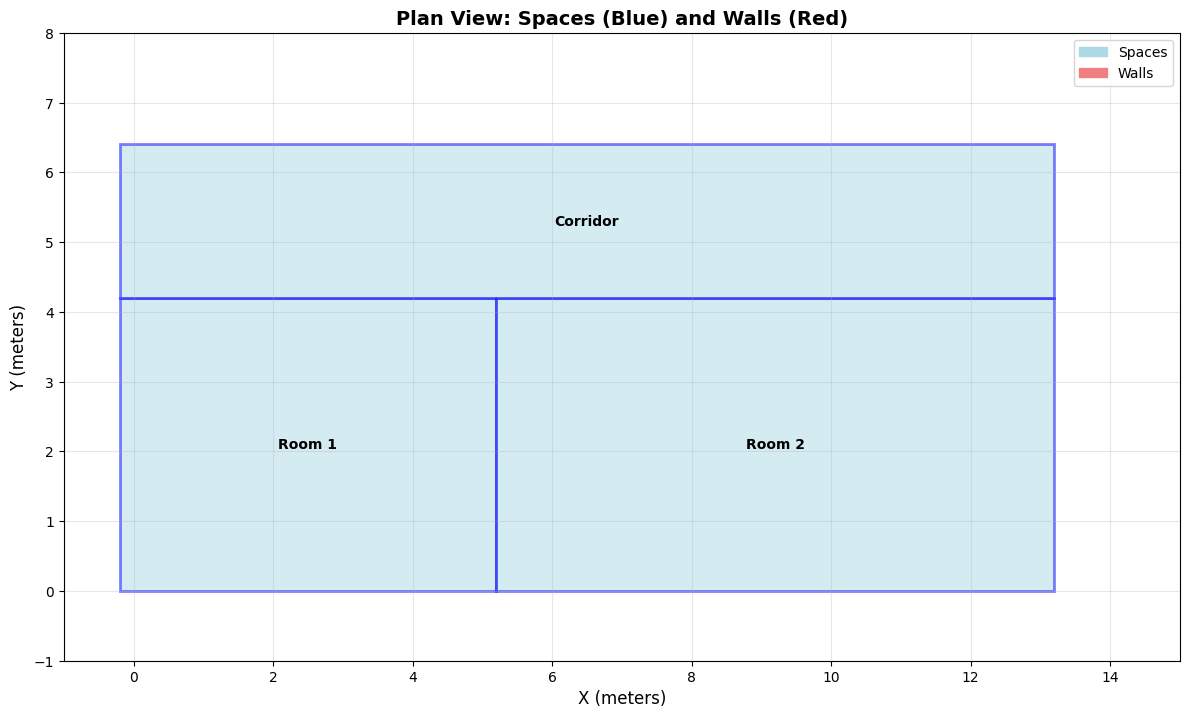

In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def visualize_plan_view():
    """Create a 2D plan view showing spaces and walls"""
    fig, ax = plt.subplots(1, 1, figsize=(12, 8))
    
    # Get all spaces
    spaces = model.by_type("IfcSpace")
    for space in spaces:
        if space.ObjectPlacement and hasattr(space.ObjectPlacement, 'RelativePlacement'):
            loc = space.ObjectPlacement.RelativePlacement.Location.Coordinates
            x, y = loc[0]/1000, loc[1]/1000  # mm to m
            
            # Extract dimensions from representation
            if space.Representation:
                for rep in space.Representation.Representations:
                    for item in rep.Items:
                        if hasattr(item, 'SweptArea'):
                            profile = item.SweptArea
                            if hasattr(profile, 'XDim') and hasattr(profile, 'YDim'):
                                width = profile.XDim / 1000
                                depth = profile.YDim / 1000
                                # Draw space as rectangle (light blue fill, blue outline)
                                rect = patches.Rectangle((x - width/2, y - depth/2), width, depth,
                                    linewidth=2, edgecolor='blue', facecolor='lightblue', alpha=0.5)
                                ax.add_patch(rect)
                                # Add label
                                ax.text(x, y, space.Name or 'Space', ha='center', va='center',
                                    fontsize=10, fontweight='bold')
    
    # Get all walls
    walls = model.by_type("IfcWall")
    for wall in walls:
        if wall.ObjectPlacement and hasattr(wall.ObjectPlacement, 'RelativePlacement'):
            placement = wall.ObjectPlacement.RelativePlacement
            loc = placement.Location.Coordinates
            x, y = loc[0]/1000, loc[1]/1000
            
            # Get rotation (if any)
            if hasattr(placement, 'Axis'):
                rotation = 0
            else:
                rotation = 0
            
            # Extract wall dimensions from representation
            if wall.Representation:
                for rep in wall.Representation.Representations:
                    for item in rep.Items:
                        if hasattr(item, 'SweptArea'):
                            profile = item.SweptArea
                            if hasattr(profile, 'XDim') and hasattr(profile, 'YDim'):
                                length = profile.XDim / 1000
                                thickness = profile.YDim / 1000
                                # Draw wall as rectangle (dark outline)
                                rect = patches.Rectangle((x - length/2, y - thickness/2), length, thickness,
                                    linewidth=2, edgecolor='darkred', facecolor='lightcoral', alpha=0.7)
                                ax.add_patch(rect)
    
    ax.set_xlim(-1, 15)
    ax.set_ylim(-1, 8)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.set_xlabel('X (meters)', fontsize=12)
    ax.set_ylabel('Y (meters)', fontsize=12)
    ax.set_title('Plan View: Spaces (Blue) and Walls (Red)', fontsize=14, fontweight='bold')
    
    # Add legend
    blue_patch = patches.Patch(color='lightblue', edgecolor='blue', label='Spaces')
    red_patch = patches.Patch(color='lightcoral', edgecolor='darkred', label='Walls')
    ax.legend(handles=[blue_patch, red_patch], loc='upper right')
    
    plt.tight_layout()
    plt.show()

visualize_plan_view()


In [14]:
print(doorrep)

#355=IfcShapeRepresentation(#13,'Body','SweptSolid',(#354))


In [15]:
model.write("test.ifc")